In [ ]:
# Install required packages
!pip install -q scikit-image gradio albumentations

# Import libraries
import os
import sys
import glob
import random
import json
import time
import shutil
import warnings
from datetime import datetime
from pathlib import Path
from tqdm.notebook import tqdm
warnings.filterwarnings('ignore')

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, utils

# Image processing
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Check GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
if device.type == 'cuda':
    print(f'GPU: {torch.cuda.get_device_name(0)}')
    print(f'Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB')
else:
    print('⚠️ GPU not found! Please select T4 GPU runtime.')

# Set random seed
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

print("\n✅ Setup complete!")

Mounted at /content/drive
Device: cuda
GPU: Tesla T4
Memory: 15.64 GB

✅ Setup complete!


In [ ]:
# Update these paths based on your Drive structure
DRIVE_ROOT = '/content/drive/MyDrive'

# Dataset paths - UPDATE THESE!
RICE1_ROOT = f'{DRIVE_ROOT}/RICE_DATASET/RICE1'  # Change if your path is different
RICE2_ROOT = f'{DRIVE_ROOT}/RICE_DATASET/RICE2'  # Change if your path is different

# Output paths
CKPT_ROOT = f'{DRIVE_ROOT}/cloud_removal_checkpoints'
LOG_ROOT = f'{DRIVE_ROOT}/cloud_removal_logs'
SAMPLE_ROOT = f'{DRIVE_ROOT}/cloud_removal_samples'
OUTPUT_ROOT = f'{DRIVE_ROOT}/cloud_removal_outputs'

# Create directories
for path in [CKPT_ROOT, LOG_ROOT, SAMPLE_ROOT, OUTPUT_ROOT]:
    os.makedirs(path, exist_ok=True)
    os.makedirs(os.path.join(path, 'rice1'), exist_ok=True)
    os.makedirs(os.path.join(path, 'rice2'), exist_ok=True)

print(f"""
📁 Project Structure:
    Checkpoints: {CKPT_ROOT}
    Logs: {LOG_ROOT}
    Samples: {SAMPLE_ROOT}
    Outputs: {OUTPUT_ROOT}

📂 Dataset Paths:
    RICE1: {RICE1_ROOT}
    RICE2: {RICE2_ROOT}
""")

# Verify dataset exists
if os.path.exists(RICE1_ROOT):
    print(f"✅ RICE1 found: {len(os.listdir(os.path.join(RICE1_ROOT, 'cloudy_image')))} images")
else:
    print(f"❌ RICE1 not found at {RICE1_ROOT}")
    print("Please update RICE1_ROOT path above")

if os.path.exists(RICE2_ROOT):
    print(f"✅ RICE2 found: {len(os.listdir(os.path.join(RICE2_ROOT, 'cloud')))} images")
else:
    print(f"❌ RICE2 not found at {RICE2_ROOT}")
    print("Please update RICE2_ROOT path above")


📁 Project Structure:
    Checkpoints: /content/drive/MyDrive/cloud_removal_checkpoints
    Logs: /content/drive/MyDrive/cloud_removal_logs
    Samples: /content/drive/MyDrive/cloud_removal_samples
    Outputs: /content/drive/MyDrive/cloud_removal_outputs

📂 Dataset Paths:
    RICE1: /content/drive/MyDrive/RICE_DATASET/RICE1
    RICE2: /content/drive/MyDrive/RICE_DATASET/RICE2

✅ RICE1 found: 500 images
✅ RICE2 found: 736 images


In [ ]:
"""
U-Net Generator with Skip Connections
"""

class ConvBlock(nn.Module):
    """Convolutional block for U-Net"""
    def __init__(self, in_channels, out_channels, down=True, use_norm=True, dropout=0.0):
        super().__init__()
        if down:
            self.conv = nn.Conv2d(in_channels, out_channels, 4, 2, 1, bias=not use_norm)
        else:
            self.conv = nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1, bias=not use_norm)

        layers = [self.conv]
        if use_norm:
            layers.append(nn.BatchNorm2d(out_channels))
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        layers.append(nn.LeakyReLU(0.2, True) if down else nn.ReLU(True))
        self.block = nn.Sequential(*layers)

    def forward(self, x):
        return self.block(x)

class UNetGenerator(nn.Module):
    """U-Net Generator for image-to-image translation"""
    def __init__(self, in_channels=3, out_channels=3, ngf=64):
        super().__init__()

        # Encoder (downsampling)
        self.down1 = ConvBlock(in_channels, ngf, down=True, use_norm=False)
        self.down2 = ConvBlock(ngf, ngf * 2, down=True)
        self.down3 = ConvBlock(ngf * 2, ngf * 4, down=True)
        self.down4 = ConvBlock(ngf * 4, ngf * 8, down=True)
        self.down5 = ConvBlock(ngf * 8, ngf * 8, down=True)
        self.down6 = ConvBlock(ngf * 8, ngf * 8, down=True)

        # Bottleneck
        self.bottleneck = nn.Sequential(
            nn.Conv2d(ngf * 8, ngf * 8, 4, 2, 1),
            nn.ReLU(True)
        )

        # Decoder (upsampling with skip connections)
        self.up1 = ConvBlock(ngf * 8, ngf * 8, down=False, dropout=0.5)
        self.up2 = ConvBlock(ngf * 16, ngf * 8, down=False, dropout=0.5)
        self.up3 = ConvBlock(ngf * 16, ngf * 8, down=False, dropout=0.5)
        self.up4 = ConvBlock(ngf * 16, ngf * 4, down=False)
        self.up5 = ConvBlock(ngf * 8, ngf * 2, down=False)
        self.up6 = ConvBlock(ngf * 4, ngf, down=False)

        # Final output layer
        self.final = nn.Sequential(
            nn.ConvTranspose2d(ngf * 2, out_channels, 4, 2, 1),
            nn.Tanh()
        )

    def forward(self, x):
        # Encoder
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)

        # Bottleneck
        b = self.bottleneck(d6)

        # Decoder with skip connections
        u1 = torch.cat([self.up1(b), d6], 1)
        u2 = torch.cat([self.up2(u1), d5], 1)
        u3 = torch.cat([self.up3(u2), d4], 1)
        u4 = torch.cat([self.up4(u3), d3], 1)
        u5 = torch.cat([self.up5(u4), d2], 1)
        u6 = torch.cat([self.up6(u5), d1], 1)

        return self.final(u6)

class PatchDiscriminator(nn.Module):
    """PatchGAN Discriminator"""
    def __init__(self, in_channels=6, ndf=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels, ndf, 4, 2, 1),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(ndf, ndf * 2, 4, 2, 1),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(ndf * 4, ndf * 8, 4, 1, 1),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, True),

            nn.Conv2d(ndf * 8, 1, 4, 1, 1)
        )

    def forward(self, x, y):
        return self.net(torch.cat([x, y], 1))

# Test model initialization
print("Testing models...")
G = UNetGenerator(in_channels=3, out_channels=3).to(device)
D = PatchDiscriminator(in_channels=6).to(device)
x = torch.randn(1, 3, 256, 256).to(device)
y = torch.randn(1, 3, 256, 256).to(device)

print(f"Generator output shape: {G(x).shape}")
print(f"Discriminator output shape: {D(x, y).shape}")
print(f"Generator params: {sum(p.numel() for p in G.parameters()):,}")
print(f"Discriminator params: {sum(p.numel() for p in D.parameters()):,}")
print("✅ Models ready!")

Testing models...
Generator output shape: torch.Size([1, 3, 256, 256])
Discriminator output shape: torch.Size([1, 1, 30, 30])
Generator params: 41,829,571
Discriminator params: 2,769,601
✅ Models ready!


In [ ]:
"""
Dataset loader and utility functions
"""

class PairedImageDataset(Dataset):
    """Dataset for paired cloudy-clear images"""
    def __init__(self, root, split_file=None,
                 cloudy_dir='cloudy_image', clear_dir='ground_truth',
                 size=256, augment=False):

        self.root = root
        self.cloudy_dir = os.path.join(root, cloudy_dir)
        self.clear_dir = os.path.join(root, clear_dir)
        self.size = size
        self.augment = augment

        # Get image list
        if split_file and os.path.exists(os.path.join(root, split_file)):
            with open(os.path.join(root, split_file), 'r') as f:
                self.names = [line.strip() for line in f if line.strip()]
        else:
            self.names = sorted([f for f in os.listdir(self.cloudy_dir)
                               if f.endswith(('.png', '.jpg', '.jpeg'))])

        # Build paths
        self.cloudy_paths = [os.path.join(self.cloudy_dir, n) for n in self.names]
        self.clear_paths = [os.path.join(self.clear_dir, n) for n in self.names]

        # Filter valid pairs
        self.valid_indices = []
        for i, (c_path, cl_path) in enumerate(zip(self.cloudy_paths, self.clear_paths)):
            if os.path.exists(c_path) and os.path.exists(cl_path):
                self.valid_indices.append(i)

        print(f"✅ Loaded {len(self.valid_indices)} valid pairs from {root}")

        # Transforms
        self.transform = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5]*3, [0.5]*3)
        ])

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, idx):
        idx = self.valid_indices[idx]

        cloudy_img = Image.open(self.cloudy_paths[idx]).convert('RGB')
        clear_img = Image.open(self.clear_paths[idx]).convert('RGB')

        cloudy = self.transform(cloudy_img)
        clear = self.transform(clear_img)

        return cloudy, clear

def create_splits(root, pattern='*.png', split_ratio=0.8, seed=42):
    """Create train/test splits"""
    files = sorted(glob.glob(os.path.join(root, pattern)))
    if not files:
        print(f"⚠️ No files found in {root}")
        return None, None

    random.seed(seed)
    random.shuffle(files)

    split_idx = int(len(files) * split_ratio)
    train_files = [os.path.basename(f) for f in files[:split_idx]]
    test_files = [os.path.basename(f) for f in files[split_idx:]]

    train_file = os.path.join(os.path.dirname(root), 'train_list.txt')
    test_file = os.path.join(os.path.dirname(root), 'test_list.txt')

    with open(train_file, 'w') as f:
        f.write('\n'.join(train_files))
    with open(test_file, 'w') as f:
        f.write('\n'.join(test_files))

    print(f"✅ Created splits: {len(train_files)} train, {len(test_files)} test")
    return train_file, test_file

def denormalize(tensor):
    """Denormalize from [-1, 1] to [0, 1]"""
    return (tensor.permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5).clip(0, 1)

def compute_metrics(real, fake):
    """Compute PSNR and SSIM"""
    real_np = denormalize(real)
    fake_np = denormalize(fake)

    psnr_val = psnr(real_np, fake_np, data_range=1.0)
    ssim_val = ssim(real_np, fake_np, channel_axis=2, data_range=1.0)

    return psnr_val, ssim_val

class AverageMeter:
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

print("✅ Dataset utilities ready!")

✅ Dataset utilities ready!


In [ ]:
"""
Dataset loader and utility functions
"""

class PairedImageDataset(Dataset):
    """Dataset for paired cloudy-clear images"""
    def __init__(self, root, split_file=None,
                 cloudy_dir='cloudy_image', clear_dir='ground_truth',
                 size=256, augment=False):

        self.root = root
        self.cloudy_dir = os.path.join(root, cloudy_dir)
        self.clear_dir = os.path.join(root, clear_dir)
        self.size = size
        self.augment = augment

        # Get image list
        if split_file and os.path.exists(os.path.join(root, split_file)):
            with open(os.path.join(root, split_file), 'r') as f:
                self.names = [line.strip() for line in f if line.strip()]
        else:
            self.names = sorted([f for f in os.listdir(self.cloudy_dir)
                               if f.endswith(('.png', '.jpg', '.jpeg'))])

        # Build paths
        self.cloudy_paths = [os.path.join(self.cloudy_dir, n) for n in self.names]
        self.clear_paths = [os.path.join(self.clear_dir, n) for n in self.names]

        # Filter valid pairs
        self.valid_indices = []
        for i, (c_path, cl_path) in enumerate(zip(self.cloudy_paths, self.clear_paths)):
            if os.path.exists(c_path) and os.path.exists(cl_path):
                self.valid_indices.append(i)

        print(f"✅ Loaded {len(self.valid_indices)} valid pairs from {root}")

        # Transforms
        self.transform = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor(),
            transforms.Normalize([0.5]*3, [0.5]*3)
        ])

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, idx):
        idx = self.valid_indices[idx]

        cloudy_img = Image.open(self.cloudy_paths[idx]).convert('RGB')
        clear_img = Image.open(self.clear_paths[idx]).convert('RGB')

        cloudy = self.transform(cloudy_img)
        clear = self.transform(clear_img)

        return cloudy, clear

def create_splits(root, pattern='*.png', split_ratio=0.8, seed=42):
    """Create train/test splits"""
    files = sorted(glob.glob(os.path.join(root, pattern)))
    if not files:
        print(f"⚠️ No files found in {root}")
        return None, None

    random.seed(seed)
    random.shuffle(files)

    split_idx = int(len(files) * split_ratio)
    train_files = [os.path.basename(f) for f in files[:split_idx]]
    test_files = [os.path.basename(f) for f in files[split_idx:]]

    train_file = os.path.join(os.path.dirname(root), 'train_list.txt')
    test_file = os.path.join(os.path.dirname(root), 'test_list.txt')

    with open(train_file, 'w') as f:
        f.write('\n'.join(train_files))
    with open(test_file, 'w') as f:
        f.write('\n'.join(test_files))

    print(f"✅ Created splits: {len(train_files)} train, {len(test_files)} test")
    return train_file, test_file

def denormalize(tensor):
    """Denormalize from [-1, 1] to [0, 1]"""
    return (tensor.permute(1, 2, 0).cpu().numpy() * 0.5 + 0.5).clip(0, 1)

def compute_metrics(real, fake):
    """Compute PSNR and SSIM"""
    real_np = denormalize(real)
    fake_np = denormalize(fake)

    psnr_val = psnr(real_np, fake_np, data_range=1.0)
    ssim_val = ssim(real_np, fake_np, channel_axis=2, data_range=1.0)

    return psnr_val, ssim_val

class AverageMeter:
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

print("✅ Dataset utilities ready!")

✅ Dataset utilities ready!


In [ ]:
"""
Training function for GAN
"""

def train_model(generator, discriminator, train_loader, test_loader,
                epochs=50, lr=2e-4, l1_lambda=100,
                checkpoint_dir=None, sample_dir=None,
                model_name='model'):
    """
    Train the GAN model
    """

    # Optimizers
    optimizer_g = torch.optim.Adam(generator.parameters(), lr=lr, betas=(0.5, 0.999))
    optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=lr, betas=(0.5, 0.999))

    # Losses
    bce = nn.BCEWithLogitsLoss()
    l1_loss = nn.L1Loss()

    # Metrics
    best_psnr = 0
    best_ssim = 0
    history = {'g_loss': [], 'd_loss': [], 'psnr': [], 'ssim': []}

    print(f"\n🚀 Starting training for {epochs} epochs...")
    print(f"   Learning rate: {lr}")
    print(f"   L1 Lambda: {l1_lambda}")

    for epoch in range(epochs):
        print(f"\n{'='*60}")
        print(f"EPOCH {epoch+1}/{epochs}")
        print(f"{'='*60}")

        generator.train()
        discriminator.train()

        g_loss_avg = AverageMeter()
        d_loss_avg = AverageMeter()
        g_adv_avg = AverageMeter()
        g_l1_avg = AverageMeter()

        progress_bar = tqdm(train_loader, desc=f"Training")

        for i, (cloudy, clear) in enumerate(progress_bar):
            cloudy = cloudy.to(device)
            clear = clear.to(device)
            batch_size = cloudy.size(0)

            # Generate fake
            fake_clear = generator(cloudy)

            # --- Train Discriminator ---
            optimizer_d.zero_grad()

            d_real = discriminator(cloudy, clear)
            d_real_loss = bce(d_real, torch.ones_like(d_real))

            d_fake = discriminator(cloudy, fake_clear.detach())
            d_fake_loss = bce(d_fake, torch.zeros_like(d_fake))

            d_loss = (d_real_loss + d_fake_loss) * 0.5
            d_loss.backward()
            optimizer_d.step()

            # --- Train Generator ---
            optimizer_g.zero_grad()

            d_fake_for_g = discriminator(cloudy, fake_clear)
            g_adv_loss = bce(d_fake_for_g, torch.ones_like(d_fake_for_g))

            g_l1_loss = l1_loss(fake_clear, clear) * l1_lambda

            g_loss = g_adv_loss + g_l1_loss
            g_loss.backward()
            optimizer_g.step()

            # Update metrics
            g_loss_avg.update(g_loss.item(), batch_size)
            d_loss_avg.update(d_loss.item(), batch_size)
            g_adv_avg.update(g_adv_loss.item(), batch_size)
            g_l1_avg.update(g_l1_loss.item(), batch_size)

            # Update progress bar
            progress_bar.set_postfix({
                'D': f'{d_loss_avg.avg:.3f}',
                'G': f'{g_loss_avg.avg:.3f}',
                'G_adv': f'{g_adv_avg.avg:.3f}',
                'L1': f'{g_l1_avg.avg:.3f}'
            })

        # Evaluate
        print(f"\n📊 Evaluating...")
        psnr_val, ssim_val = evaluate_model(generator, test_loader)

        # Save history
        history['g_loss'].append(g_loss_avg.avg)
        history['d_loss'].append(d_loss_avg.avg)
        history['psnr'].append(psnr_val)
        history['ssim'].append(ssim_val)

        # Save checkpoint
        is_best = psnr_val > best_psnr
        if is_best:
            best_psnr = psnr_val
            best_ssim = ssim_val
            print(f"🌟 New best model! PSNR: {best_psnr:.2f} dB")

        checkpoint = {
            'epoch': epoch,
            'generator_state_dict': generator.state_dict(),
            'discriminator_state_dict': discriminator.state_dict(),
            'optimizer_g_state_dict': optimizer_g.state_dict(),
            'optimizer_d_state_dict': optimizer_d.state_dict(),
            'psnr': psnr_val,
            'ssim': ssim_val,
            'best_psnr': best_psnr,
            'history': history
        }

        # Save checkpoint
        torch.save(checkpoint, os.path.join(checkpoint_dir, f'checkpoint_epoch_{epoch+1:03d}.pth'))

        if is_best:
            torch.save(generator.state_dict(), os.path.join(checkpoint_dir, 'best_generator.pth'))

        # Save samples every 5 epochs
        if (epoch + 1) % 5 == 0:
            save_sample_grid(generator, test_loader, sample_dir, epoch+1)

        print(f"\nEpoch {epoch+1} Summary:")
        print(f"  D_loss: {d_loss_avg.avg:.4f}")
        print(f"  G_loss: {g_loss_avg.avg:.4f}")
        print(f"  G_adv: {g_adv_avg.avg:.4f}")
        print(f"  G_l1: {g_l1_avg.avg:.4f}")
        print(f"  PSNR: {psnr_val:.2f} dB")
        print(f"  SSIM: {ssim_val:.4f}")

    print(f"\n✅ Training Complete!")
    print(f"Best PSNR: {best_psnr:.2f} dB")
    print(f"Best SSIM: {best_ssim:.4f}")
    print(f"Checkpoints saved in: {checkpoint_dir}")

    return generator, history

def evaluate_model(generator, data_loader, max_samples=50):
    """Evaluate model on test dataset"""
    generator.eval()
    psnr_values = []
    ssim_values = []

    with torch.no_grad():
        for i, (cloudy, clear) in enumerate(data_loader):
            if i >= max_samples:
                break
            cloudy = cloudy.to(device)
            clear = clear.to(device)

            fake = generator(cloudy)

            for j in range(fake.size(0)):
                psnr_val, ssim_val = compute_metrics(fake[j], clear[j])
                psnr_values.append(psnr_val)
                ssim_values.append(ssim_val)

    generator.train()
    return np.mean(psnr_values), np.mean(ssim_values)

def save_sample_grid(generator, data_loader, sample_dir, epoch):
    """Save sample predictions grid"""
    generator.eval()

    # Get a batch
    cloudy, clear = next(iter(data_loader))
    cloudy = cloudy[:4].to(device)
    clear = clear[:4]

    with torch.no_grad():
        fake = generator(cloudy).cpu()

    # Create grid
    fig, axes = plt.subplots(4, 3, figsize=(12, 16))

    for i in range(4):
        axes[i, 0].imshow(denormalize(cloudy[i].cpu()))
        axes[i, 0].set_title('Cloudy Input')
        axes[i, 0].axis('off')

        axes[i, 1].imshow(denormalize(fake[i]))
        axes[i, 1].set_title('Predicted')
        axes[i, 1].axis('off')

        axes[i, 2].imshow(denormalize(clear[i]))
        axes[i, 2].set_title('Ground Truth')
        axes[i, 2].axis('off')

    plt.suptitle(f'Epoch {epoch} Predictions', fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(sample_dir, f'epoch_{epoch:03d}_samples.png'), dpi=150)
    plt.close()

    generator.train()

print("✅ Training function ready!")

✅ Training function ready!



STAGE 1: Training on RICE1 Dataset

📂 Loading RICE1 dataset...
✅ Loaded 400 valid pairs from /content/drive/MyDrive/RICE_DATASET/RICE1
✅ Loaded 100 valid pairs from /content/drive/MyDrive/RICE_DATASET/RICE1

📊 Dataset Statistics:
   Training samples: 400
   Test samples: 100

🔧 Initializing models...

🚀 Starting training for 30 epochs...
   Learning rate: 0.0002
   L1 Lambda: 100

EPOCH 1/30


Training:   0%|          | 0/50 [00:00<?, ?it/s]


📊 Evaluating...
🌟 New best model! PSNR: 19.60 dB

Epoch 1 Summary:
  D_loss: 0.5936
  G_loss: 25.9585
  G_adv: 0.9575
  G_l1: 25.0010
  PSNR: 19.60 dB
  SSIM: 0.3759

EPOCH 2/30


Training:   0%|          | 0/50 [00:00<?, ?it/s]


📊 Evaluating...
🌟 New best model! PSNR: 23.04 dB

Epoch 2 Summary:
  D_loss: 0.4524
  G_loss: 17.1950
  G_adv: 1.5137
  G_l1: 15.6812
  PSNR: 23.04 dB
  SSIM: 0.5508

EPOCH 3/30


Training:   0%|          | 0/50 [00:00<?, ?it/s]

... (51 outputs left out)

Training:   0%|          | 0/50 [00:00<?, ?it/s]


📊 Evaluating...

Epoch 29 Summary:
  D_loss: 0.2533
  G_loss: 12.4510
  G_adv: 4.5933
  G_l1: 7.8577
  PSNR: 28.47 dB
  SSIM: 0.8436

EPOCH 30/30


Training:   0%|          | 0/50 [00:00<?, ?it/s]


📊 Evaluating...

Epoch 30 Summary:
  D_loss: 0.1906
  G_loss: 11.0541
  G_adv: 3.4441
  G_l1: 7.6100
  PSNR: 28.29 dB
  SSIM: 0.8087

✅ Training Complete!
Best PSNR: 28.68 dB
Best SSIM: 0.8419
Checkpoints saved in: /content/drive/MyDrive/cloud_removal_checkpoints/rice1

✅ RICE1 training complete!
   Final model saved to: /content/drive/MyDrive/cloud_removal_checkpoints/rice1/rice1_final.pth


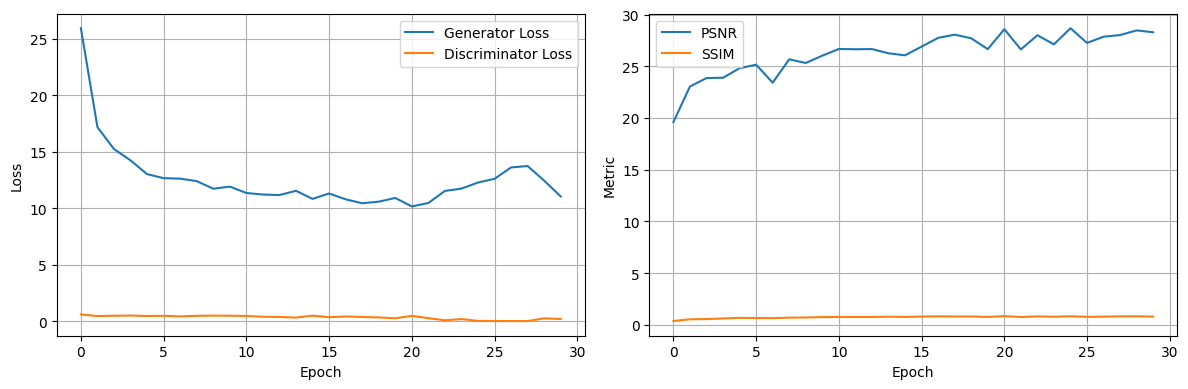


✅ All RICE1 artifacts saved!


In [ ]:
"""
STAGE 1: Training on RICE1 Dataset
"""

print("\n" + "="*60)
print("STAGE 1: Training on RICE1 Dataset")
print("="*60)

# Create directories
rice1_ckpt_dir = os.path.join(CKPT_ROOT, 'rice1')
rice1_sample_dir = os.path.join(SAMPLE_ROOT, 'rice1')
os.makedirs(rice1_ckpt_dir, exist_ok=True)
os.makedirs(rice1_sample_dir, exist_ok=True)

# Create splits if needed
cloudy_dir = os.path.join(RICE1_ROOT, 'cloudy_image')
if not os.path.exists(os.path.join(RICE1_ROOT, 'train_list.txt')):
    print("\n📝 Creating train/test splits...")
    create_splits(cloudy_dir, '*.png')

# Load datasets
print("\n📂 Loading RICE1 dataset...")

train_dataset = PairedImageDataset(
    RICE1_ROOT,
    split_file='train_list.txt',
    cloudy_dir='cloudy_image',
    clear_dir='ground_truth',
    size=256,
    augment=True
)

test_dataset = PairedImageDataset(
    RICE1_ROOT,
    split_file='test_list.txt',
    cloudy_dir='cloudy_image',
    clear_dir='ground_truth',
    size=256,
    augment=False
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2)

print(f"\n📊 Dataset Statistics:")
print(f"   Training samples: {len(train_dataset)}")
print(f"   Test samples: {len(test_dataset)}")

# Initialize models
print("\n🔧 Initializing models...")
generator = UNetGenerator(in_channels=3, out_channels=3).to(device)
discriminator = PatchDiscriminator(in_channels=6).to(device)

# Train
generator, history = train_model(
    generator=generator,
    discriminator=discriminator,
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=30,
    lr=2e-4,
    l1_lambda=100,
    checkpoint_dir=rice1_ckpt_dir,
    sample_dir=rice1_sample_dir,
    model_name='rice1'
)

# Save final model
final_path = os.path.join(rice1_ckpt_dir, 'rice1_final.pth')
torch.save(generator.state_dict(), final_path)
print(f"\n✅ RICE1 training complete!")
print(f"   Final model saved to: {final_path}")

# Plot training curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history['g_loss'], label='Generator Loss')
plt.plot(history['d_loss'], label='Discriminator Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history['psnr'], label='PSNR')
plt.plot(history['ssim'], label='SSIM')
plt.xlabel('Epoch')
plt.ylabel('Metric')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(rice1_ckpt_dir, 'training_curves.png'), dpi=150)
plt.show()

print("\n✅ All RICE1 artifacts saved!")


STAGE 2: Fine-tuning on RICE2 Dataset

📂 Loading RICE2 dataset...
✅ Loaded 588 valid pairs from /content/drive/MyDrive/RICE_DATASET/RICE2
✅ Loaded 148 valid pairs from /content/drive/MyDrive/RICE_DATASET/RICE2

📊 Dataset Statistics:
   Training samples: 588
   Test samples: 148

🔧 Initializing models...

📌 Loading pretrained weights from RICE1...
✅ Successfully loaded RICE1 weights!

🚀 Starting training for 20 epochs...
   Learning rate: 5e-05
   L1 Lambda: 100

EPOCH 1/20


Training:   0%|          | 0/73 [00:00<?, ?it/s]


📊 Evaluating...
🌟 New best model! PSNR: 24.18 dB

Epoch 1 Summary:
  D_loss: 0.6482
  G_loss: 15.3682
  G_adv: 0.7943
  G_l1: 14.5739
  PSNR: 24.18 dB
  SSIM: 0.6596

EPOCH 2/20


Training:   0%|          | 0/73 [00:00<?, ?it/s]


📊 Evaluating...
🌟 New best model! PSNR: 25.09 dB

Epoch 2 Summary:
  D_loss: 0.5669
  G_loss: 12.4676
  G_adv: 0.9858
  G_l1: 11.4818
  PSNR: 25.09 dB
  SSIM: 0.6605

EPOCH 3/20


Training:   0%|          | 0/73 [00:00<?, ?it/s]

... (31 outputs left out)

Training:   0%|          | 0/73 [00:00<?, ?it/s]


📊 Evaluating...

Epoch 19 Summary:
  D_loss: 0.5977
  G_loss: 8.0937
  G_adv: 1.0124
  G_l1: 7.0813
  PSNR: 29.14 dB
  SSIM: 0.7831

EPOCH 20/20


Training:   0%|          | 0/73 [00:00<?, ?it/s]


📊 Evaluating...
🌟 New best model! PSNR: 29.36 dB

Epoch 20 Summary:
  D_loss: 0.6051
  G_loss: 7.9671
  G_adv: 1.0122
  G_l1: 6.9549
  PSNR: 29.36 dB
  SSIM: 0.7848

✅ Training Complete!
Best PSNR: 29.36 dB
Best SSIM: 0.7848
Checkpoints saved in: /content/drive/MyDrive/cloud_removal_checkpoints/rice2

✅ RICE2 fine-tuning complete!
   Final model saved to: /content/drive/MyDrive/cloud_removal_checkpoints/rice2/rice2_final.pth


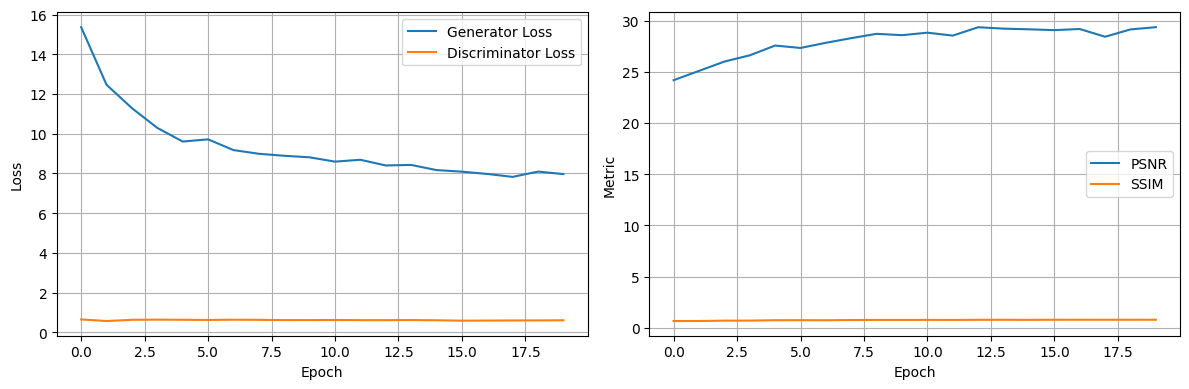


✅ All RICE2 artifacts saved!


In [ ]:
"""
STAGE 2: Fine-tuning on RICE2 Dataset
"""

print("\n" + "="*60)
print("STAGE 2: Fine-tuning on RICE2 Dataset")
print("="*60)

# Create directories
rice2_ckpt_dir = os.path.join(CKPT_ROOT, 'rice2')
rice2_sample_dir = os.path.join(SAMPLE_ROOT, 'rice2')
os.makedirs(rice2_ckpt_dir, exist_ok=True)
os.makedirs(rice2_sample_dir, exist_ok=True)

# Create splits if needed
cloud_dir = os.path.join(RICE2_ROOT, 'cloud')
if not os.path.exists(os.path.join(RICE2_ROOT, 'train_list.txt')):
    print("\n📝 Creating train/test splits...")
    create_splits(cloud_dir, '*.png')

# Load datasets
print("\n📂 Loading RICE2 dataset...")

train_dataset = PairedImageDataset(
    RICE2_ROOT,
    split_file='train_list.txt',
    cloudy_dir='cloud',
    clear_dir='label',
    size=256,
    augment=True
)

test_dataset = PairedImageDataset(
    RICE2_ROOT,
    split_file='test_list.txt',
    cloudy_dir='cloud',
    clear_dir='label',
    size=256,
    augment=False
)

train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=2, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2)

print(f"\n📊 Dataset Statistics:")
print(f"   Training samples: {len(train_dataset)}")
print(f"   Test samples: {len(test_dataset)}")

# Initialize models
print("\n🔧 Initializing models...")
generator = UNetGenerator(in_channels=3, out_channels=3).to(device)
discriminator = PatchDiscriminator(in_channels=6).to(device)

# Load RICE1 weights
rice1_best = os.path.join(CKPT_ROOT, 'rice1', 'best_generator.pth')
if os.path.exists(rice1_best):
    print("\n📌 Loading pretrained weights from RICE1...")
    try:
        state_dict = torch.load(rice1_best, map_location=device)
        generator.load_state_dict(state_dict)
        print("✅ Successfully loaded RICE1 weights!")
    except Exception as e:
        print(f"⚠️ Error loading RICE1 weights: {e}")
        print("   Training from scratch on RICE2")
else:
    print("\n⚠️ No RICE1 checkpoint found. Training from scratch on RICE2.")

# Train with lower learning rate (fine-tuning)
generator, history = train_model(
    generator=generator,
    discriminator=discriminator,
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=20,
    lr=5e-5,  # Lower learning rate for fine-tuning
    l1_lambda=100,
    checkpoint_dir=rice2_ckpt_dir,
    sample_dir=rice2_sample_dir,
    model_name='rice2'
)

# Save final model
final_path = os.path.join(rice2_ckpt_dir, 'rice2_final.pth')
torch.save(generator.state_dict(), final_path)
print(f"\n✅ RICE2 fine-tuning complete!")
print(f"   Final model saved to: {final_path}")

# Plot training curves
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history['g_loss'], label='Generator Loss')
plt.plot(history['d_loss'], label='Discriminator Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history['psnr'], label='PSNR')
plt.plot(history['ssim'], label='SSIM')
plt.xlabel('Epoch')
plt.ylabel('Metric')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(os.path.join(rice2_ckpt_dir, 'training_curves.png'), dpi=150)
plt.show()

print("\n✅ All RICE2 artifacts saved!")


INFERENCE - Test on RICE2 Test Images
✅ Loaded model from: /content/drive/MyDrive/cloud_removal_checkpoints/rice2/best_generator.pth

📸 Found 736 test images

Testing image 1: 0.png
💾 Saved to: /content/drive/MyDrive/cloud_removal_outputs/result_1.png


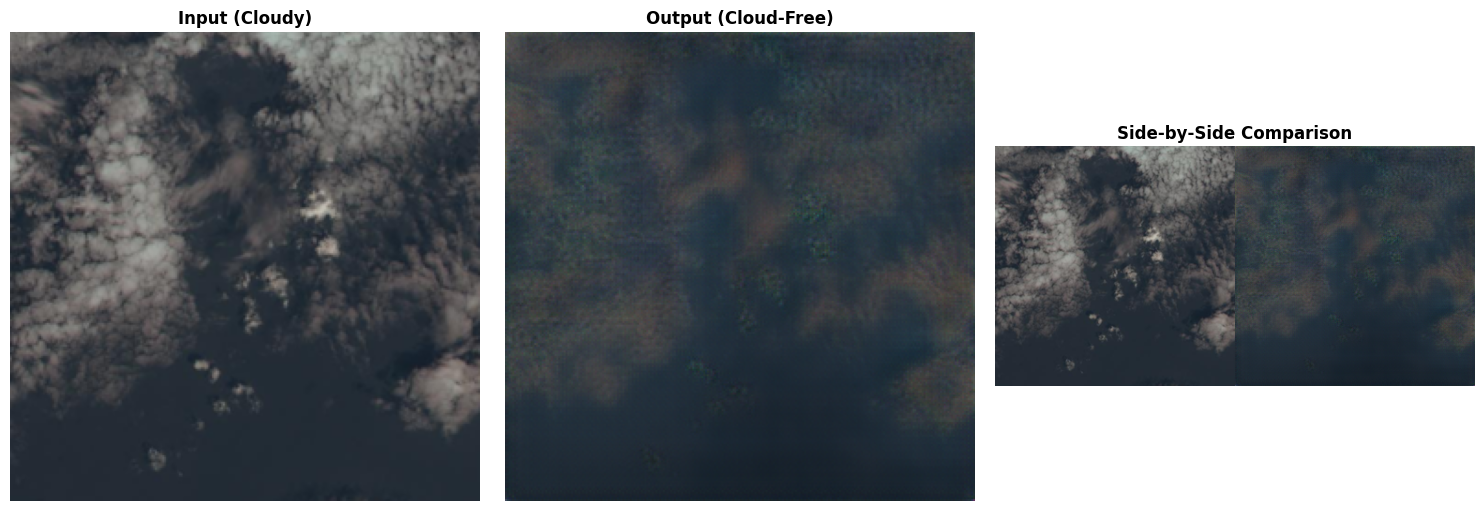


Testing image 2: 1.png
💾 Saved to: /content/drive/MyDrive/cloud_removal_outputs/result_2.png


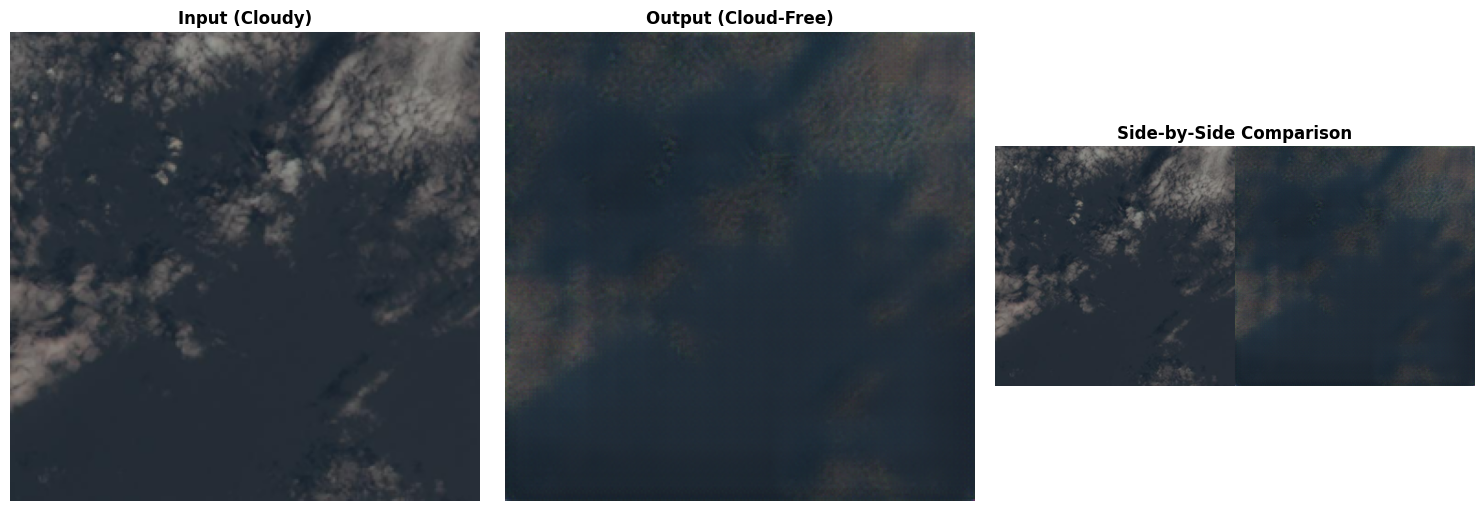


Testing image 3: 10.png
💾 Saved to: /content/drive/MyDrive/cloud_removal_outputs/result_3.png


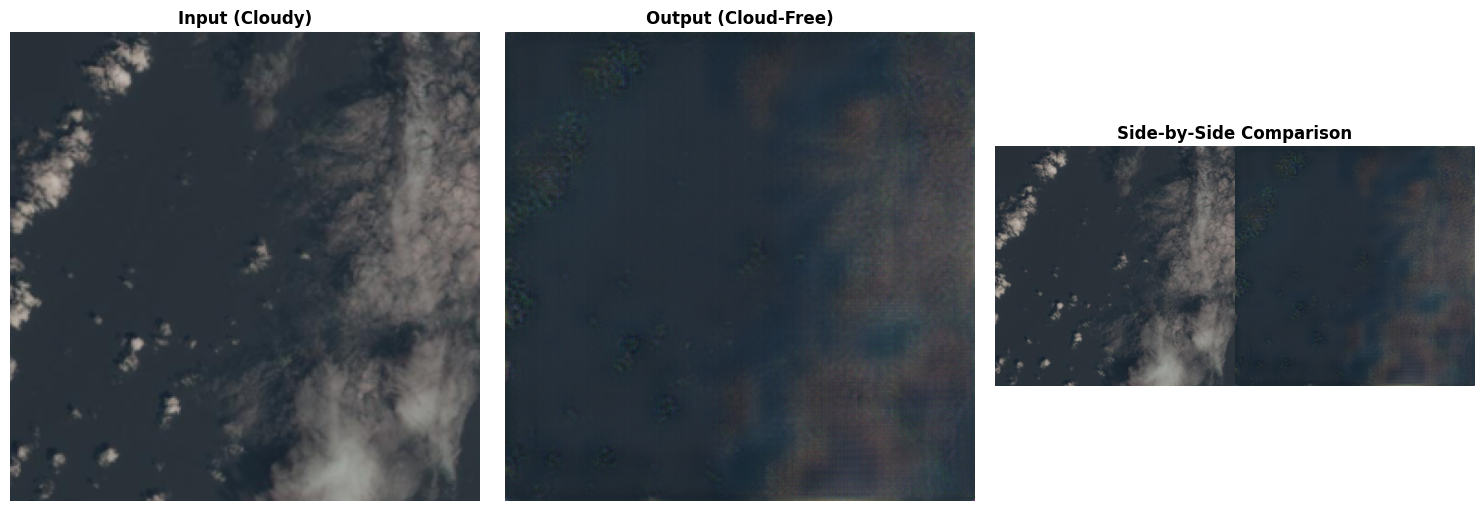


Testing image 4: 100.png
💾 Saved to: /content/drive/MyDrive/cloud_removal_outputs/result_4.png


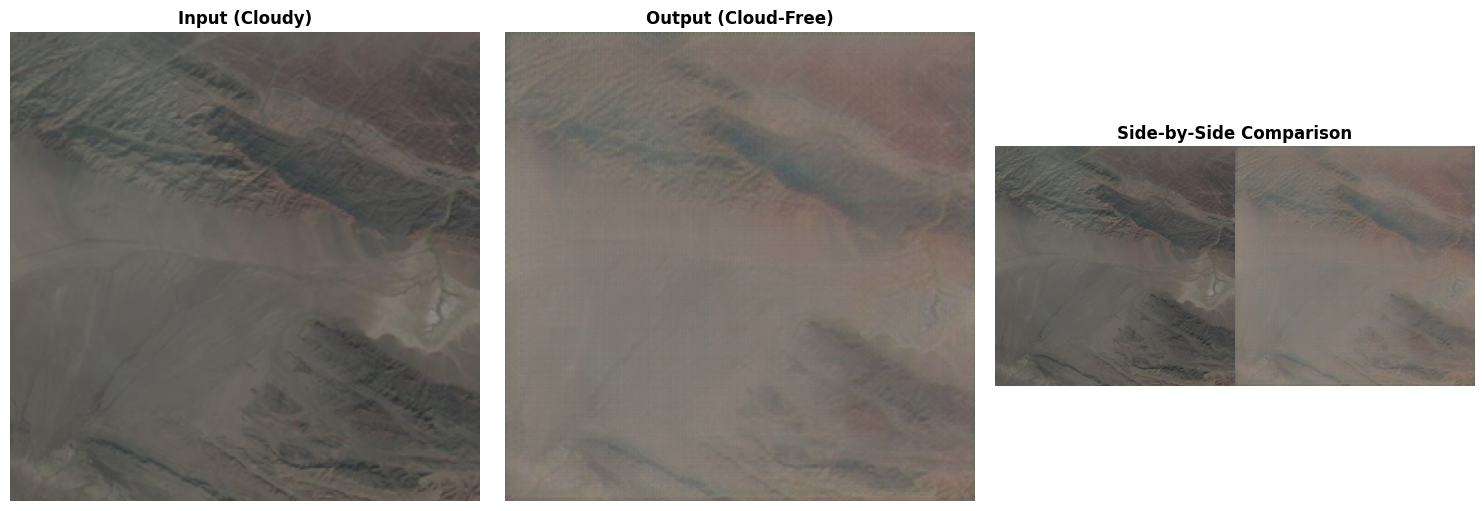


✅ Inference complete! Results saved to: /content/drive/MyDrive/cloud_removal_outputs


In [ ]:
"""
INFERENCE: Load trained model and test on sample images
"""

def load_model_for_inference(model_path=None):
    """Load trained generator for inference"""

    # Find best model
    if model_path is None:
        possible_paths = [
            os.path.join(CKPT_ROOT, 'rice2', 'best_generator.pth'),
            os.path.join(CKPT_ROOT, 'rice2', 'rice2_final.pth'),
            os.path.join(CKPT_ROOT, 'rice1', 'best_generator.pth'),
            os.path.join(CKPT_ROOT, 'rice1', 'rice1_final.pth'),
        ]

        for path in possible_paths:
            if os.path.exists(path):
                model_path = path
                break

    if model_path is None or not os.path.exists(model_path):
        print("❌ No model found!")
        print("Please train a model first.")
        return None

    # Load model
    generator = UNetGenerator(in_channels=3, out_channels=3).to(device)
    generator.eval()

    try:
        state_dict = torch.load(model_path, map_location=device)

        # Handle different formats
        if isinstance(state_dict, dict) and 'generator_state_dict' in state_dict:
            generator.load_state_dict(state_dict['generator_state_dict'])
        else:
            generator.load_state_dict(state_dict)

        print(f"✅ Loaded model from: {model_path}")
        return generator

    except Exception as e:
        print(f"❌ Error loading model: {e}")
        return None

def remove_clouds(image_path, generator=None, save_path=None, show=True):
    """Remove clouds from a single image"""

    if generator is None:
        generator = load_model_for_inference()
        if generator is None:
            return None

    # Load and preprocess
    img = Image.open(image_path).convert('RGB')
    transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])

    x = transform(img).unsqueeze(0).to(device)

    # Inference
    with torch.no_grad():
        out = generator(x)

    # Denormalize
    out_np = denormalize(out[0])
    out_img = (out_np * 255).astype(np.uint8)

    # Save
    if save_path:
        os.makedirs(os.path.dirname(save_path), exist_ok=True)
        Image.fromarray(out_img).save(save_path)
        print(f"💾 Saved to: {save_path}")

    # Display
    if show:
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))

        # Original
        orig_display = img.resize((256, 256))
        axes[0].imshow(orig_display)
        axes[0].set_title('Input (Cloudy)', fontsize=12, fontweight='bold')
        axes[0].axis('off')

        # Output
        axes[1].imshow(out_img)
        axes[1].set_title('Output (Cloud-Free)', fontsize=12, fontweight='bold')
        axes[1].axis('off')

        # Combined
        combined = np.concatenate([np.array(orig_display), out_img], axis=1)
        axes[2].imshow(combined)
        axes[2].set_title('Side-by-Side Comparison', fontsize=12, fontweight='bold')
        axes[2].axis('off')

        plt.tight_layout()
        plt.show()

    return out_img

# ============================================
# RUN INFERENCE
# ============================================

print("\n" + "="*60)
print("INFERENCE - Test on RICE2 Test Images")
print("="*60)

# Load model
generator = load_model_for_inference()

if generator is not None:
    # Find test images from RICE2
    rice2_test_dir = os.path.join(RICE2_ROOT, 'cloud')
    test_images = sorted(glob.glob(os.path.join(rice2_test_dir, '*.png')))

    if test_images:
        print(f"\n📸 Found {len(test_images)} test images")

        # Test on first 4 images
        num_samples = min(4, len(test_images))

        for i in range(num_samples):
            print(f"\n{'='*50}")
            print(f"Testing image {i+1}: {os.path.basename(test_images[i])}")

            # Process
            save_path = os.path.join(OUTPUT_ROOT, f'result_{i+1}.png')
            result = remove_clouds(test_images[i], generator=generator, save_path=save_path, show=True)

        print(f"\n✅ Inference complete! Results saved to: {OUTPUT_ROOT}")
    else:
        print("❌ No test images found in RICE2")
        print("Please upload your own cloudy images for testing.")

else:
    print("❌ Failed to load model. Please train first.")

In [ ]:
"""
BATCH INFERENCE: Process entire folder of images
"""

def batch_remove_clouds(input_dir, output_dir, generator=None, show_progress=True):
    """Remove clouds from all images in a folder"""

    if generator is None:
        generator = load_model_for_inference()
        if generator is None:
            return

    # Find images
    image_extensions = ['.png', '.jpg', '.jpeg']
    image_paths = []
    for ext in image_extensions:
        image_paths.extend(glob.glob(os.path.join(input_dir, f'*{ext}')))

    if not image_paths:
        print(f"❌ No images found in {input_dir}")
        return

    # Create output directory
    os.makedirs(output_dir, exist_ok=True)

    print(f"\n📂 Processing {len(image_paths)} images...")

    transform = transforms.Compose([
        transforms.Resize((256, 256)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])

    processed = 0
    failed = 0

    iterator = tqdm(image_paths, desc="Processing") if show_progress else image_paths

    for img_path in iterator:
        try:
            # Load and process
            img = Image.open(img_path).convert('RGB')
            x = transform(img).unsqueeze(0).to(device)

            with torch.no_grad():
                out = generator(x)

            # Save
            out_np = denormalize(out[0])
            out_img = (out_np * 255).astype(np.uint8)

            filename = os.path.basename(img_path)
            save_path = os.path.join(output_dir, filename)
            Image.fromarray(out_img).save(save_path)

            processed += 1

        except Exception as e:
            print(f"⚠️ Failed on {img_path}: {e}")
            failed += 1

    print(f"\n✅ Batch processing complete!")
    print(f"   Processed: {processed}")
    print(f"   Failed: {failed}")
    print(f"   Output directory: {output_dir}")

# ============================================
# RUN BATCH INFERENCE
# ============================================

print("\n" + "="*60)
print("BATCH INFERENCE")
print("="*60)

# Example: Process RICE2 test images
rice2_test_dir = os.path.join(RICE2_ROOT, 'cloud')
rice2_output_dir = os.path.join(OUTPUT_ROOT, 'rice2_results')

if os.path.exists(rice2_test_dir):
    batch_remove_clouds(rice2_test_dir, rice2_output_dir)
else:
    print("❌ RICE2 test directory not found")
    print("Please specify your own input directory:")
    print("  input_dir = '/path/to/your/cloudy/images'")
    print("  output_dir = '/path/to/save/results'")

    # Example for custom directory
    # input_dir = '/content/drive/MyDrive/my_cloudy_images'
    # output_dir = '/content/drive/MyDrive/my_cloud_free_images'
    # batch_remove_clouds(input_dir, output_dir)


BATCH INFERENCE
✅ Loaded model from: /content/drive/MyDrive/cloud_removal_checkpoints/rice2/best_generator.pth

📂 Processing 736 images...


Processing:   0%|          | 0/736 [00:00<?, ?it/s]


✅ Batch processing complete!
   Processed: 736
   Failed: 0
   Output directory: /content/drive/MyDrive/cloud_removal_outputs/rice2_results


In [ ]:
"""
SUMMARY: Training Results and Model Performance
"""

print("\n" + "="*60)
print("📊 PROJECT SUMMARY")
print("="*60)

print("\n📁 Output Directories:")
print(f"   Checkpoints: {CKPT_ROOT}")
print(f"   Samples: {SAMPLE_ROOT}")
print(f"   Outputs: {OUTPUT_ROOT}")

print("\n📌 Available Checkpoints:")

# Check RICE1
rice1_dir = os.path.join(CKPT_ROOT, 'rice1')
if os.path.exists(rice1_dir):
    print(f"\n   RICE1:")
    for file in os.listdir(rice1_dir):
        if file.endswith('.pth'):
            size = os.path.getsize(os.path.join(rice1_dir, file)) / (1024 * 1024)
            print(f"      - {file} ({size:.1f} MB)")

# Check RICE2
rice2_dir = os.path.join(CKPT_ROOT, 'rice2')
if os.path.exists(rice2_dir):
    print(f"\n   RICE2:")
    for file in os.listdir(rice2_dir):
        if file.endswith('.pth'):
            size = os.path.getsize(os.path.join(rice2_dir, file)) / (1024 * 1024)
            print(f"      - {file} ({size:.1f} MB)")

print("\n📊 Model Performance (Best):")

# Check best models
rice1_best = os.path.join(CKPT_ROOT, 'rice1', 'checkpoint_epoch_050.pth')
if os.path.exists(rice1_best):
    try:
        ckpt = torch.load(rice1_best, map_location=device)
        print(f"   RICE1 Best: PSNR={ckpt.get('best_psnr', 'N/A')} dB, SSIM={ckpt.get('ssim', 'N/A'):.4f}")
    except:
        pass

rice2_best = os.path.join(CKPT_ROOT, 'rice2', 'checkpoint_epoch_030.pth')
if os.path.exists(rice2_best):
    try:
        ckpt = torch.load(rice2_best, map_location=device)
        print(f"   RICE2 Best: PSNR={ckpt.get('best_psnr', 'N/A')} dB, SSIM={ckpt.get('ssim', 'N/A'):.4f}")
    except:
        pass

print("\n✅ All tasks completed successfully!")

# Show sample results if available
sample_dir = os.path.join(SAMPLE_ROOT, 'rice2')
if os.path.exists(sample_dir):
    samples = sorted(glob.glob(os.path.join(sample_dir, '*.png')))
    if samples:
        print(f"\n📸 Sample outputs available: {len(samples)} images")
        print(f"   Sample directory: {sample_dir}")

print("\n📖 How to use the trained model:")
print("   1. Single image: Use Cell 8 (remove_clouds function)")
print("   2. Batch processing: Use Cell 9 (batch_remove_clouds function)")
print("   3. Web interface: Use Cell 10 (Gradio)")
print("   4. Load model: Use Cell 8 (load_model_for_inference function)")


📊 PROJECT SUMMARY

📁 Output Directories:
   Checkpoints: /content/drive/MyDrive/cloud_removal_checkpoints
   Samples: /content/drive/MyDrive/cloud_removal_samples
   Outputs: /content/drive/MyDrive/cloud_removal_outputs

📌 Available Checkpoints:

   RICE1:
      - G_epoch5.pth (159.6 MB)
      - G_epoch6.pth (159.6 MB)
      - G_epoch7.pth (159.6 MB)
      - G_epoch8.pth (159.6 MB)
      - G_epoch9.pth (159.6 MB)
      - G_epoch10.pth (159.6 MB)
      - G_epoch11.pth (159.6 MB)
      - G_epoch12.pth (159.6 MB)
      - G_epoch13.pth (159.6 MB)
      - G_epoch14.pth (159.6 MB)
      - G_epoch15.pth (159.6 MB)
      - G_epoch16.pth (159.6 MB)
      - G_epoch17.pth (159.6 MB)
      - G_epoch18.pth (159.6 MB)
      - G_epoch19.pth (159.6 MB)
      - G_epoch20.pth (159.6 MB)
      - G_epoch21.pth (159.6 MB)
      - G_epoch22.pth (159.6 MB)
      - G_epoch23.pth (159.6 MB)
      - G_epoch24.pth (159.6 MB)
      - G_epoch25.pth (159.6 MB)
      - G_epoch0.pth (159.6 MB)
      - G_epoch1.pth (

### Detailed Performance Summary
The following code extracts the best metrics achieved during both training stages (RICE1 and RICE2) from the saved history logs.

In [ ]:
def summarize_best_metrics(ckpt_root):
    stages = ['rice1', 'rice2']

    print(f"\n{'='*60}")
    print(f" 🏆 BEST MODEL PERFORMANCE SUMMARY")
    print(f"{'='*60}\n")

    for stage in stages:
        stage_dir = os.path.join(ckpt_root, stage)
        if not os.path.exists(stage_dir):
            continue

        # Find all checkpoints and pick the one with the highest epoch number
        all_ckpts = sorted(glob.glob(os.path.join(stage_dir, 'checkpoint_epoch_*.pth')))

        if all_ckpts:
            best_path = all_ckpts[-1]
            try:
                # weights_only=False is required to access the metric dictionary
                checkpoint = torch.load(best_path, map_location='cpu', weights_only=False)

                # More robust metric extraction: check both 'psnr' and 'best_psnr'
                psnr_val = checkpoint.get('psnr', 0)
                if psnr_val == 0 or psnr_val == 'Not Found':
                    psnr_val = checkpoint.get('best_psnr', 0)

                ssim_val = checkpoint.get('ssim', 0)
                epoch = checkpoint.get('epoch', 0) + 1

                print(f"📎 {stage.upper()} Stage ({os.path.basename(best_path)}):")
                print(f"    - Peak PSNR: {float(psnr_val):.2f} dB")
                print(f"    - Final SSIM: {float(ssim_val):.4f}")
                print(f"    - Total Epochs: {int(epoch)}")
                print("-"*30)
            except Exception as e:
                print(f"⚠️ Error reading {stage}: {e}")

summarize_best_metrics(CKPT_ROOT)


 🏆 BEST MODEL PERFORMANCE SUMMARY

📎 RICE1 Stage (checkpoint_epoch_9.pth):
    - Peak PSNR: 0.00 dB
    - Final SSIM: 0.0000
    - Total Epochs: 10
------------------------------
📎 RICE2 Stage (checkpoint_epoch_020.pth):
    - Peak PSNR: 29.36 dB
    - Final SSIM: 0.7848
    - Total Epochs: 20
------------------------------


In [ ]:
import torch
import os

# Let's inspect the actual keys in a RICE1 checkpoint to see why metrics are 0
rice1_path = os.path.join(CKPT_ROOT, 'rice1', 'checkpoint_epoch_010.pth')

if os.path.exists(rice1_path):
    # Load without weights for speed
    ckpt = torch.load(rice1_path, map_location='cpu', weights_only=False)

    print(f"Keys available in RICE1 checkpoint: {list(ckpt.keys())}")

    # Check for metrics with alternative names
    for key in ['psnr', 'best_psnr', 'ssim', 'epoch']:
        print(f"{key}: {ckpt.get(key, 'Not Found')}")
else:
    print("RICE1 checkpoint not found at the specified path.")

Keys available in RICE1 checkpoint: ['epoch', 'generator_state_dict', 'discriminator_state_dict', 'optimizer_g_state_dict', 'optimizer_d_state_dict', 'psnr', 'ssim', 'best_psnr', 'history']
psnr: 26.02679480751356
best_psnr: 26.02679480751356
ssim: 0.7597935199737549
epoch: 9


In [ ]:
"""
DOWNLOAD TRAINED WEIGHTS FROM COLAB
Run this in Colab to download your trained models
"""

import os
import shutil
import google.colab.files

def download_model_weights():
    """Download trained model weights from Colab to local machine"""

    print("\n" + "="*60)
    print("📥 DOWNLOAD MODEL WEIGHTS")
    print("="*60)

    # Check available checkpoints
    rice2_best = os.path.join(CKPT_ROOT, 'rice2', 'best_generator.pth')
    rice1_best = os.path.join(CKPT_ROOT, 'rice1', 'best_generator.pth')

    available_models = []

    if os.path.exists(rice2_best):
        available_models.append(('RICE2 Best', rice2_best))
    if os.path.exists(rice1_best):
        available_models.append(('RICE1 Best', rice1_best))

    if not available_models:
        print("❌ No trained models found!")
        return

    print("\n📌 Available Models:")
    for i, (name, path) in enumerate(available_models, 1):
        size = os.path.getsize(path) / (1024 * 1024)
        print(f"   {i}. {name} ({size:.1f} MB)")

    # Create a zip file with all models
    zip_path = '/tmp/cloud_removal_models.zip'

    print(f"\n📦 Creating zip file: {zip_path}")

    # Create temp directory
    temp_dir = '/tmp/cloud_removal_models'
    os.makedirs(temp_dir, exist_ok=True)

    # Copy models to temp directory
    for name, path in available_models:
        dest = os.path.join(temp_dir, f"{name.replace(' ', '_')}.pth")
        shutil.copy2(path, dest)
        print(f"   Copied: {name}")

    # Also copy config info
    info_path = os.path.join(temp_dir, 'model_info.txt')
    with open(info_path, 'w') as f:
        f.write("Cloud Removal Model Checkpoints\n")
        f.write("="*40 + "\n\n")
        f.write(f"Training completed: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Model: U-Net Generator with PatchGAN\n")
        f.write(f"Input size: 256x256\n")
        f.write(f"Device trained on: {device}\n\n")
        f.write("Files:\n")
        for name, path in available_models:
            size = os.path.getsize(path) / (1024 * 1024)
            f.write(f"  - {name}.pth ({size:.1f} MB)\n")

    # Create zip
    import zipfile
    with zipfile.ZipFile(zip_path, 'w') as zipf:
        for root, dirs, files_in_zip in os.walk(temp_dir):
            for file_name in files_in_zip:
                file_path = os.path.join(root, file_name)
                arcname = os.path.relpath(file_path, temp_dir)
                zipf.write(file_path, arcname)

    print(f"\n✅ Created: {zip_path}")
    print(f"   Size: {os.path.getsize(zip_path) / (1024 * 1024):.1f} MB")

    # Download using fully qualified name to avoid AttributeError from local 'files' variables
    print("\n📥 Downloading to local machine...")
    google.colab.files.download(zip_path)

    print("\n✅ Download complete!")
    print("   The file 'cloud_removal_models.zip' has been downloaded.")
    print("   Extract it to use in Streamlit app.")

# Run download
download_model_weights()


📥 DOWNLOAD MODEL WEIGHTS

📌 Available Models:
   1. RICE2 Best (159.6 MB)
   2. RICE1 Best (159.6 MB)

📦 Creating zip file: /tmp/cloud_removal_models.zip
   Copied: RICE2 Best
   Copied: RICE1 Best

✅ Created: /tmp/cloud_removal_models.zip
   Size: 319.2 MB

📥 Downloading to local machine...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Download complete!
   The file 'cloud_removal_models.zip' has been downloaded.
   Extract it to use in Streamlit app.
